# 2026 지옥캠프: 6공학관 vs IT관 분류 — EfficientNet-B0

EfficientNet-B0를 잠정 채택했습니다. 같은 데이터 분할에서 시드 42·43·44·45로 4회 학습하고, epoch별 CSV와 실행별 그래프·통계를 저장합니다. 네 가지 증강과 비율 보존 256×256 입력을 사용하고, 각 모델의 최저 검증 Log Loss 가중치를 선택합니다. 전원 일치 시 확률 평균에 T=0.3, 불일치 시 가운데 두 확률 평균에 T=0.7을 적용해 제출합니다.

- 작성 환경: Google Colab (CPU만으로도 동작) / 로컬 Python 3.10+, PyTorch 2.x
- GPU가 있으면 자동으로 사용하지만 **필수는 아닙니다**

## 대회 규칙 요약 (필독)

| 항목 | 내용 |
|---|---|
| 과제 | 사진 → **6공학관(0) / IT관(1)** 이진 분류 |
| 참가 | 개인전 |
| 기간 | 2026-11-07(토) ~ 11-08(일) |
| 지표 | **Log Loss** (낮을수록 우수, 확률을 제출해야 함) |
| 모델 제약 | **총 파라미터 20M 이하** (앙상블·사전학습 백본 합산) |
| 런타임 | **Colab CPU 기준** 테스트 500장 10분 이내 · 실행 중 다운로드 금지 (사전학습 가중치는 최종 파일에 포함) |
| 금지 | 외부 이미지 사용, 테스트 이미지를 학습에 사용(pseudo-labeling 포함) |
| 제출 | 예측 CSV **10분에 1회 · 하루 최대 50회** (공개 리더보드) + 마감 시 최종 파일 1개 (형식 자유) |
| 순위 | 테스트 500장 중 Public 250장 = 공개 리더보드, **Private 250장 = 최종 순위** (어느 장이 Private 인지는 비공개) |


## 실행 전 사전 준비

### 모듈
Colab은 필요한 모듈이 모두 설치되어 있습니다. 로컬이라면:
```shell
# 본인 환경(CPU/CUDA)에 맞는 PyTorch 설치: https://pytorch.org/get-started/locally/
pip3 install torch torchvision
pip3 install -U scikit-learn matplotlib
```

### 데이터 파일
운영진이 배포한 데이터를 노트북과 같은 폴더에 압축해제해 주세요 (Colab 은 `/content`).
```
📁root
 ├─📁train
 │  ├─📁6e      ← 6공학관 (label 0)
 │  └─📁it      ← IT관   (label 1)
 ├─📁test       ← 테스트 500장 (Public 250 + Private 250)
 └─📜baseline.ipynb
```


## 모듈 불러오기 & 시드 고정

재현성을 위해 모든 난수 시드를 고정합니다. 시드가 고정되어 있어야 "내가 바꾼 것 때문에 점수가 오른 것인지, 운이 좋았던 것인지"를 구분할 수 있습니다.

In [ ]:
import csv
import os
import random
import shutil
import subprocess
import time

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import Image


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 1
seed_everything(SEED)

In [49]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('사용 장치:', device)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name())

사용 장치: cuda:0
NVIDIA GeForce RTX 3080


## 하이퍼 파라미터

In [50]:
params = {
    'epoch': 50,
    'early_stopping': True,
    'min_epochs': 5,       # 각 학습률의 최소 학습 epoch, 이후부터 미개선 횟수 집계
    'patience': 5,
    'batch_size': 32,
    'learning_rates': (1e-3, 3e-4, 1e-4),
    'valid_ratio': 0.15,   # 학습 2,906장 중 검증으로 떼어둘 비율
    'workers': 0,          # Windows 노트북의 워커 프로세스 멈춤 방지; 모든 실험에 공통 적용
    'num_show_img': 5,     # 데이터 확인용 표시 개수 (학습과 무관)
}

In [51]:
# label 0 = 6공학관(6e), label 1 = IT관(it)
class_names = {0: '6e', 1: 'it'}

RUN_SEEDS = (42, 43, 44, 45)
AUGMENTATION_BY_SEED = {42: "basic", 43: "strong", 44: "erasing", 45: "perspective"}


## 결과 폴더

실행별 그래프는 `실험결과/005_LogLoss4모델_비율보존/graphs`, 학습 가중치는 `실험결과/005_LogLoss4모델_비율보존/checkpoints`, 통계 CSV는 `실험결과/005_LogLoss4모델_비율보존`에 저장합니다.
각 epoch의 학습·검증 Log Loss와 정확도는 `실험결과/005_LogLoss4모델_비율보존/epochs/efficientnet_b0_seed{시드}.csv`에 즉시 저장합니다.
같은 시드로 다시 실행하면 해당 결과 파일을 덮어씁니다.


In [52]:
from pathlib import Path

BASE_DIR = Path.cwd().resolve()
assert (BASE_DIR / "train").is_dir(), f"작업 폴더에 train이 없습니다: {BASE_DIR}"

RESULT_DIR = BASE_DIR / "실험결과" / "005_LogLoss4모델_비율보존"
GRAPH_DIR = RESULT_DIR / "graphs"
CHECKPOINT_DIR = RESULT_DIR / "checkpoints"
EPOCH_DIR = RESULT_DIR / "epochs"

GRAPH_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
EPOCH_DIR.mkdir(parents=True, exist_ok=True)

print("그래프 저장 폴더:", GRAPH_DIR)
print("학습 가중치 저장 폴더:", CHECKPOINT_DIR)

print("epoch CSV 저장 폴더:", EPOCH_DIR)


그래프 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\graphs
학습 가중치 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints
epoch CSV 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\epochs


## 모델 정의 (`model.py` 생성)

EfficientNet-B0는 이진 분류용 logit 1개를 출력합니다.
학습 시 `pretrained=True`로 ImageNet 사전학습 가중치를 불러와 전체 파라미터를 학습합니다.
Torchvision은 최초 학습 때 가중치를 다운로드하고 이후 캐시를 재사용합니다.
`pretrained=False`는 구조만 생성하므로 제출 패키지에서 다운로드 없이 최종 가중치를 불러올 수 있습니다.


In [53]:
%%writefile model.py
import torch
import torch.nn as nn
from torchvision import models
from torchvision import transforms
from torchvision.transforms import functional as F

IMG_SIZE = 256
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)
PAD_FILL = tuple(round(value * 255) for value in NORM_MEAN)
CONSENSUS_TEMPERATURE = 0.3
DISAGREEMENT_TEMPERATURE = 0.7


def resize_pad(image):
	width, height = image.size
	scale = IMG_SIZE / max(width, height)
	new_width = max(1, round(width * scale))
	new_height = max(1, round(height * scale))
	image = F.resize(image, [new_height, new_width], antialias=True)
	left = (IMG_SIZE - new_width) // 2
	top = (IMG_SIZE - new_height) // 2
	return F.pad(image, [left, top, IMG_SIZE - new_width - left, IMG_SIZE - new_height - top], fill=PAD_FILL)


class RandomAreaCrop:
	def __init__(self, scale):
		self.scale = scale

	def __call__(self, image):
		top, left, height, width = transforms.RandomResizedCrop.get_params(image, scale=self.scale, ratio=(0.75, 4 / 3))
		return F.crop(image, top, left, height, width)


def build_valid_transform():
	return transforms.Compose([
		transforms.Lambda(resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])


def combine_probabilities(member_probs):
	assert (member_probs.ndim == 2) and (member_probs.shape[1] == 4)
	votes = member_probs >= 0.5
	unanimous = (votes == votes[:, :1]).all(dim=1, keepdim=True)
	middle_mean = member_probs.sort(dim=1).values[:, 1:3].mean(dim=1, keepdim=True)
	probs = torch.where(unanimous, member_probs.mean(dim=1, keepdim=True), middle_mean)
	temperatures = torch.where(unanimous, CONSENSUS_TEMPERATURE, DISAGREEMENT_TEMPERATURE)
	return torch.sigmoid(torch.logit(probs) / temperatures)


def build_model(pretrained=False):
	weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
	net = models.efficientnet_b0(weights=weights)
	net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	return net


class EfficientNetEnsemble(nn.Module):
	def __init__(self, state_dicts):
		super().__init__()
		assert len(state_dicts) == 4, "앙상블 가중치 4개가 필요합니다."
		self.models = nn.ModuleList()
		for state_dict in state_dicts:
			model = build_model()
			model.load_state_dict(state_dict)
			self.models.append(model)

	def member_probabilities(self, inputs):
		return torch.cat([torch.sigmoid(model(inputs)) for model in self.models], dim=1)

	def forward(self, inputs):
		return combine_probabilities(self.member_probabilities(inputs))


Overwriting model.py


In [54]:
import importlib
import model as model_module

importlib.reload(model_module)


<module 'model' from 'c:\\Users\\행조\\OneDrive\\문서\\ChatGPT\\aid mini 대회\\model.py'>

### 파라미터 제한

각 실행에서 모델을 새로 만들고 총 파라미터 수가 20,000,000 이하인지 확인합니다.


In [55]:
PARAM_LIMIT = 20_000_000
print(f"EfficientNet-B0 {len(RUN_SEEDS)}개 / Log Loss 기준 / 의견 일치 여부에 따른 앙상블")


EfficientNet-B0 4개 / Log Loss 기준 / 의견 일치 여부에 따른 앙상블


## 데이터 불러오기 & 증강

seed 42는 기본형, 43은 강규칙형, 44는 기본형에 Random Erasing, 45는 기본형에 원근 변형을 적용합니다.
기본형은 크롭 면적 70–100%, 밝기·대비 ±30%, 채도 ±20%입니다.
강규칙형은 크롭 면적 50–100%, 밝기·대비 ±40%, 채도 ±30%입니다.
가림은 확률 10%, 면적 2–10%이며, 원근 변형은 확률 30%, distortion_scale=0.15입니다.
모두 좌우 반전 확률 0.5를 사용합니다.

학습에서는 먼저 원본에서 영역을 자르고 비율을 유지해 긴 변을 256으로 맞춘 뒤 중앙 패딩합니다.
검증·추론은 전체 원본을 같은 비율 보존·패딩 방식으로 변환합니다.
원본의 색을 보존한 평균 RGB 여백을 사용하고, 모든 입력은 256×256입니다.


In [56]:
data_path = BASE_DIR / "train"
IMG_SIZE = model_module.IMG_SIZE
NORM_MEAN = model_module.NORM_MEAN
NORM_STD = model_module.NORM_STD

AUGMENTATION_SETTINGS = {
	"basic": {"scale_min": 0.7, "brightness": 0.3, "contrast": 0.3, "saturation": 0.2, "erase_p": 0.0, "perspective_p": 0.0, "distortion_scale": 0.0},
	"strong": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.0, "distortion_scale": 0.0},
	"erasing": {"scale_min": 0.7, "brightness": 0.3, "contrast": 0.3, "saturation": 0.2, "erase_p": 0.1, "perspective_p": 0.0, "distortion_scale": 0.0},
	"perspective": {"scale_min": 0.7, "brightness": 0.3, "contrast": 0.3, "saturation": 0.2, "erase_p": 0.0, "perspective_p": 0.3, "distortion_scale": 0.15},
}
train_transforms = {}
for name, settings in AUGMENTATION_SETTINGS.items():
	operations = [
		model_module.RandomAreaCrop(scale=(settings["scale_min"], 1.0)),
		transforms.RandomHorizontalFlip(p=0.5),
		transforms.ColorJitter(brightness=settings["brightness"], contrast=settings["contrast"], saturation=settings["saturation"]),
	]
	if settings["perspective_p"] > 0:
		operations.append(transforms.RandomPerspective(distortion_scale=settings["distortion_scale"], p=settings["perspective_p"], fill=model_module.PAD_FILL))
	operations.extend([
		transforms.Lambda(model_module.resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])
	if settings["erase_p"] > 0:
		operations.append(transforms.RandomErasing(p=settings["erase_p"], scale=(0.02, 0.1), value=0))
	train_transforms[name] = transforms.Compose(operations)

train_transform = train_transforms["basic"]
valid_transform = model_module.build_valid_transform()
full_train = datasets.ImageFolder(data_path, train_transform)
full_valid = datasets.ImageFolder(data_path, valid_transform)
print("클래스 → 라벨 매핑:", full_train.class_to_idx)
print("전체 이미지 수:", len(full_train))
print("입력 크기:", IMG_SIZE, "비율 보존 및 중앙 패딩")


클래스 → 라벨 매핑: {'6e': 0, 'it': 1}
전체 이미지 수: 2906
입력 크기: 256 비율 보존 및 중앙 패딩


### Train / Valid 분할

분할 seed 42, 검증 비율 15%, 클래스 비율 유지로 고정합니다. 네 모델은 같은 학습·검증 인덱스를 사용합니다.


In [57]:
labels = [y for _, y in full_train.samples]
train_idx, valid_idx = train_test_split(
    list(range(len(full_train))),
    test_size=params['valid_ratio'],
    stratify=labels,
    random_state=SEED,
)

data_sets = {
    'train': Subset(full_train, train_idx),
    'valid': Subset(full_valid, valid_idx),
}
print(f"train: {len(data_sets['train'])}장 / valid: {len(data_sets['valid'])}장")

train: 2470장 / valid: 436장


In [58]:
g = torch.Generator()
g.manual_seed(SEED)

dataloaders = {
    'train': DataLoader(data_sets['train'], batch_size=params['batch_size'],
                        shuffle=True, num_workers=params['workers'], generator=g),
    'valid': DataLoader(data_sets['valid'], batch_size=params['batch_size'],
                        shuffle=False, num_workers=params['workers']),
}
print('배치 수 — train: %d / valid: %d' % (len(dataloaders['train']), len(dataloaders['valid'])))

배치 수 — train: 78 / valid: 14


### 데이터 확인

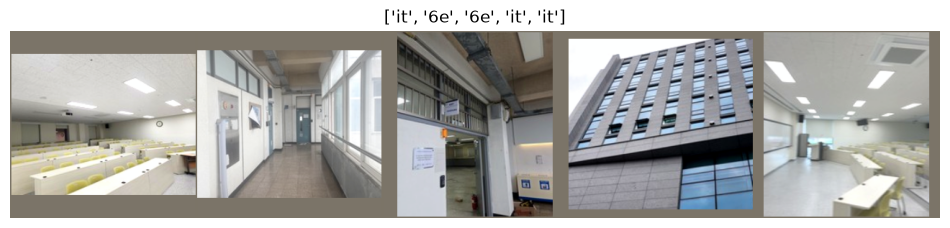

In [59]:
def img_show(tensor, title=None):
    arr = tensor.numpy().transpose((1, 2, 0))
    arr = arr * np.array(NORM_STD) + np.array(NORM_MEAN)  # 정규화 되돌리기 (표시용)
    arr = np.clip(arr, 0, 1)
    plt.figure(figsize=(12, 4))
    plt.imshow(arr)
    plt.axis('off')
    if title is not None:
        plt.title(title)
    plt.show()


inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:params['num_show_img']])
img_show(out, title=[class_names[int(c)] for c in classes[:params['num_show_img']]])

## 학습 — EfficientNet-B0 × 4회

시드는 42·43·44·45, 데이터 분할 seed는 42입니다. 각 실행은 ImageNet 사전학습 가중치에서 새로 시작합니다.
가중치 선택과 학습률 전환은 검증 Log Loss를 기준으로 합니다. Log Loss 동률의 가중치는 ACC가 높은 것을 선택합니다.
학습률은 0.001 → 0.0003 → 0.0001 순서입니다.
각 단계는 최소 5 epoch를 학습하고, 그 이후부터 해당 단계의 최저 검증 Log Loss를 5회 연속 갱신하지 못하면 다음 단계로 넘어갑니다.
단계가 바뀌면 단계별 최저 손실과 대기 횟수를 초기화합니다. 마지막 단계에서 같은 조건을 만족하면 종료합니다.
전체 최대 50 epoch 상한을 적용합니다. 계속 정체되면 10·20 epoch 종료 후 전환하고 30 epoch에서 종료합니다.

모든 epoch의 학습률·단계 번호·단계 내 epoch·학습/검증 손실과 정확도를 CSV에 즉시 저장합니다.
진행 막대는 표시하지 않습니다.


In [60]:
def run_epoch(model, loader, criterion, optimizer=None):
    """optimizer가 주어지면 학습, 아니면 평가. (평균 loss, 정확도)를 반환."""
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, total_correct, total_n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.float().unsqueeze(1).to(device)  # (B,) -> (B,1)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            total_loss += loss.item() * inputs.size(0)
            total_correct += (preds == targets).sum().item()
            total_n += inputs.size(0)

    return total_loss / total_n, total_correct / total_n


def train_model(model, dataloaders, criterion, optimizer, num_epochs, epoch_csv, early_stopping, min_epochs, patience, learning_rates):
	assert min_epochs > 0
	assert patience > 0
	assert len(learning_rates) > 0
	assert all(rate > 0 for rate in learning_rates)
	since = time.time()
	history = {'train_loss': [], 'train_acc': [], 'valid_loss': [], 'valid_acc': []}
	best_acc, best_loss, best_epoch = -float('inf'), float('inf'), -1
	stage_index, stage_epochs = 0, 0
	stage_best_loss = float('inf')
	epochs_without_improvement = 0
	epoch_writer = csv.writer(epoch_csv)
	epoch_writer.writerow(('epoch', 'learning_rate', 'lr_stage', 'stage_epoch', 'train_loss', 'train_acc', 'valid_loss', 'valid_acc'))

	for epoch in range(1, num_epochs + 1):
		learning_rate = learning_rates[stage_index]
		for group in optimizer.param_groups:
			group['lr'] = learning_rate
		stage_epochs += 1
		tr_loss, tr_acc = run_epoch(model, dataloaders['train'], criterion, optimizer)
		va_loss, va_acc = run_epoch(model, dataloaders['valid'], criterion)

		history['train_loss'].append(tr_loss)
		history['train_acc'].append(tr_acc)
		history['valid_loss'].append(va_loss)
		history['valid_acc'].append(va_acc)
		epoch_writer.writerow((epoch, learning_rate, stage_index + 1, stage_epochs, tr_loss, tr_acc, va_loss, va_acc))
		epoch_csv.flush()
		print(f'Epoch {epoch}/{num_epochs} | lr {learning_rate:g} | train loss {tr_loss:.4f}, acc {tr_acc:.3f} | valid loss {va_loss:.4f}, acc {va_acc:.3f}')

		if (va_loss < best_loss) or ((va_loss == best_loss) and (va_acc > best_acc)):
			best_acc, best_loss, best_epoch = va_acc, va_loss, epoch
			torch.save(model.state_dict(), pt_file_name)
			print(f'  ↳ best Log Loss 갱신! {pt_file_name} 저장')

		if va_loss < stage_best_loss:
			stage_best_loss = va_loss
			epochs_without_improvement = 0
		elif stage_epochs > min_epochs:
			epochs_without_improvement += 1

		if epochs_without_improvement >= patience:
			if stage_index + 1 < len(learning_rates):
				stage_index += 1
				stage_epochs = 0
				stage_best_loss = float('inf')
				epochs_without_improvement = 0
				print(f'다음 epoch부터 학습률 {learning_rates[stage_index]:g} 적용')
			elif early_stopping:
				print(f'조기 종료: epoch {epoch}, 마지막 학습률에서 Log Loss {patience}회 연속 미개선')
				break

	elapsed = time.time() - since
	print(f'\n학습 완료 ({elapsed // 60:.0f}분 {elapsed % 60:.0f}초)')
	print(f'best: epoch {best_epoch}, valid acc {best_acc:.4f}, log loss {best_loss:.4f}')
	return history, best_epoch, best_loss


In [61]:
results = []


모델: efficientnet_b0 / seed: 42 / 증강: basic
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2230, acc 0.909 | valid loss 0.1240, acc 0.956
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed42.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1246, acc 0.954 | valid loss 0.1326, acc 0.956
Epoch 3/50 | lr 0.001 | train loss 0.0827, acc 0.970 | valid loss 0.1052, acc 0.963
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed42.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.0752, acc 0.975 | valid loss 0.1503, acc 0.968
Epoch 5/50 | lr 0.001 | train loss 0.0541, acc 0.978 | valid loss 0.0490, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed42.pt 저장
Epoch 6/50 | lr 0.001 | train loss 0.0558, acc 0.983 | valid loss 0.0932, acc 0.972
Epoch 7/50 | lr 0.001 | train loss 0.0

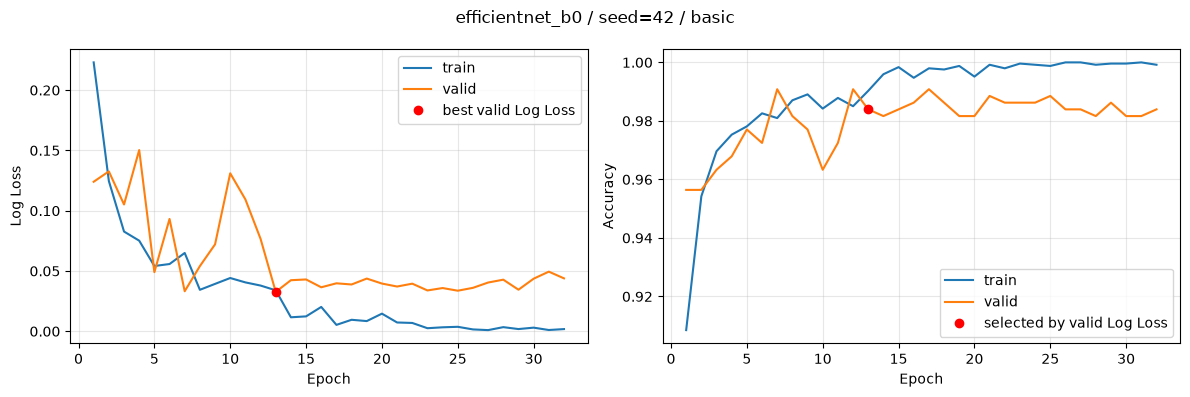


모델: efficientnet_b0 / seed: 43 / 증강: strong
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2310, acc 0.909 | valid loss 0.1155, acc 0.959
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed43.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1699, acc 0.928 | valid loss 0.0874, acc 0.972
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed43.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.0919, acc 0.965 | valid loss 0.0659, acc 0.972
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed43.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.1037, acc 0.962 | valid loss 0.1249, acc 0.959
Epoch 5/50 | lr 0.001 | train loss 0.0762, acc 0.973 | valid loss 0.0323, acc 0.986
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_se

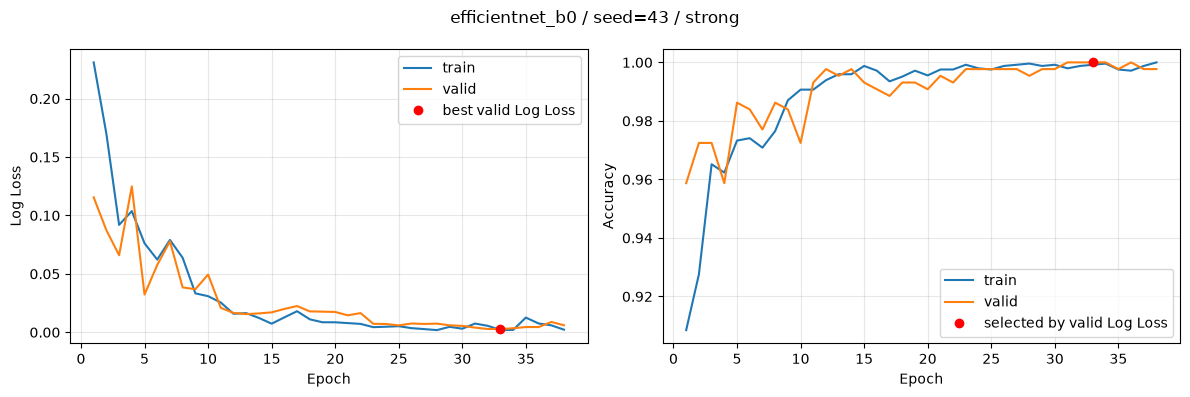


모델: efficientnet_b0 / seed: 44 / 증강: erasing
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2323, acc 0.902 | valid loss 0.1055, acc 0.959
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed44.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1323, acc 0.953 | valid loss 0.0574, acc 0.977
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed44.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.0995, acc 0.965 | valid loss 0.0733, acc 0.966
Epoch 4/50 | lr 0.001 | train loss 0.0883, acc 0.969 | valid loss 0.1201, acc 0.963
Epoch 5/50 | lr 0.001 | train loss 0.0519, acc 0.983 | valid loss 0.1034, acc 0.968
Epoch 6/50 | lr 0.001 | train loss 0.0549, acc 0.982 | valid loss 0.0615, acc 0.982
Epoch 7/50 | lr 0.001 | train loss 0.0375, acc 0.989 | valid loss 0.0620, acc 0.979
Epoch 8/50 | lr 0.001 | train loss 0.0335, acc 0.989 | valid loss 0.0730, acc 0.972


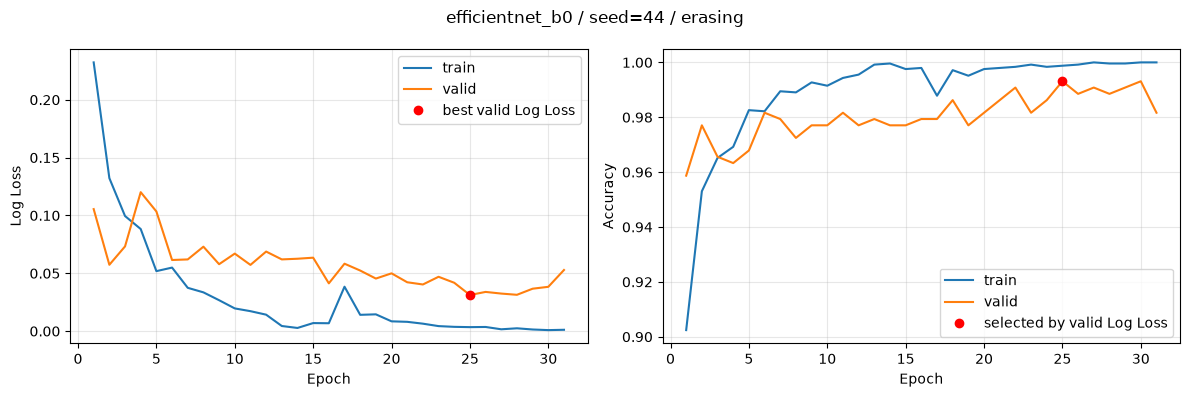


모델: efficientnet_b0 / seed: 45 / 증강: perspective
파라미터 수: 4,008,829
Epoch 1/50 | lr 0.001 | train loss 0.2236, acc 0.913 | valid loss 0.1046, acc 0.966
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed45.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1156, acc 0.957 | valid loss 0.1677, acc 0.966
Epoch 3/50 | lr 0.001 | train loss 0.1088, acc 0.966 | valid loss 0.0812, acc 0.972
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed45.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.0649, acc 0.973 | valid loss 0.0411, acc 0.986
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\checkpoints\efficientnet_b0_seed45.pt 저장
Epoch 5/50 | lr 0.001 | train loss 0.0500, acc 0.981 | valid loss 0.0487, acc 0.982
Epoch 6/50 | lr 0.001 | train loss 0.0442, acc 0.983 | valid loss 0.0903, acc 0.968
Epoch 7/50 | lr 0.001 | train lo

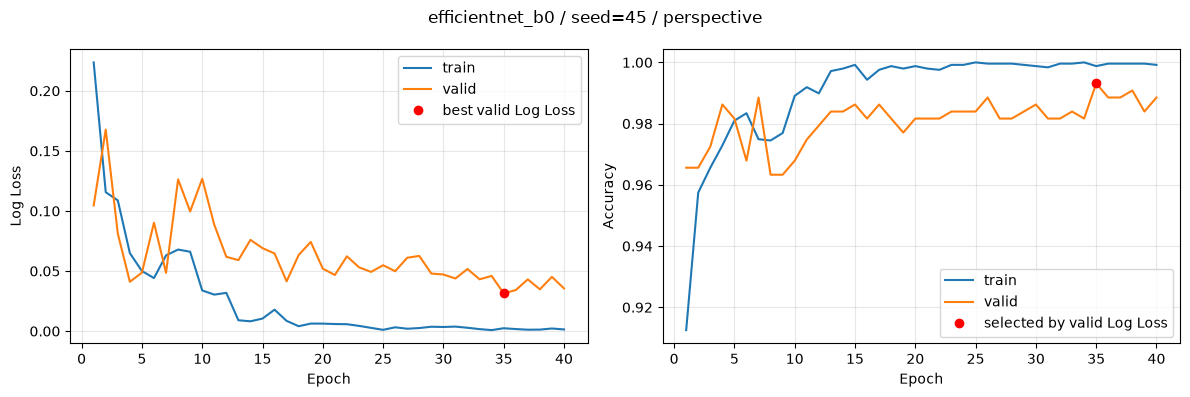

In [62]:
for seed in RUN_SEEDS:
	augmentation = AUGMENTATION_BY_SEED[seed]
	settings = AUGMENTATION_SETTINGS[augmentation]
	full_run_train = datasets.ImageFolder(data_path, train_transforms[augmentation])
	assert full_run_train.samples == full_train.samples, "이미지 순서 또는 라벨이 달라졌습니다."
	run_data_sets = {"train": Subset(full_run_train, train_idx), "valid": data_sets["valid"]}
	print(f"\n{'=' * 60}")
	print(f"모델: efficientnet_b0 / seed: {seed} / 증강: {augmentation}", flush=True)
	seed_everything(seed)

	model = model_module.build_model(pretrained=True).to(device)
	n_params = sum(p.numel() for p in model.parameters())
	assert n_params <= PARAM_LIMIT, f"파라미터 제한 초과: {n_params:,}"
	print(f"파라미터 수: {n_params:,}")

	# 모델 생성에서 소비한 난수와 데이터 로딩 난수를 분리합니다.
	seed_everything(seed)
	dataloaders = {
		"train": DataLoader(run_data_sets["train"], batch_size=params["batch_size"], shuffle=True, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
		"valid": DataLoader(run_data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
	}
	criterion = nn.BCEWithLogitsLoss()
	optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rates"][0])
	pt_file_name = CHECKPOINT_DIR / f"efficientnet_b0_seed{seed}.pt"

	if device.type == "cuda":
		torch.cuda.synchronize(device)
	started = time.perf_counter()

	with (EPOCH_DIR / f"efficientnet_b0_seed{seed}.csv").open("w", newline="", encoding="utf-8-sig") as epoch_csv:
		history, best_epoch, best_loss = train_model(model, dataloaders, criterion, optimizer, num_epochs=params["epoch"], epoch_csv=epoch_csv, early_stopping=params["early_stopping"], min_epochs=params["min_epochs"], patience=params["patience"], learning_rates=params["learning_rates"])

	if device.type == "cuda":
		torch.cuda.synchronize(device)
	elapsed = time.perf_counter() - started

	results.append({
		"model": "efficientnet_b0",
		"seed": seed,
		"augmentation": augmentation,
		"selection_metric": "valid_loss",
		"image_size": IMG_SIZE,
		"preprocessing": "crop_then_aspect_resize_pad",
		"erase_p": settings["erase_p"],
		"erase_scale": "(0.02, 0.1)",
		"perspective_p": settings["perspective_p"],
		"distortion_scale": settings["distortion_scale"],
		"scale_min": settings["scale_min"],
		"brightness": settings["brightness"],
		"contrast": settings["contrast"],
		"saturation": settings["saturation"],
		"learning_rates": str(params["learning_rates"]),
		"valid_loss_first12": min(history["valid_loss"][:12]),
		"valid_acc_first12": max(history["valid_acc"][:12]),
		"max_epochs": params["epoch"],
		"epochs_run": len(history["train_loss"]),
		"early_stopping": params["early_stopping"],
		"min_epochs": params["min_epochs"],
		"patience": params["patience"],
		"best_epoch": best_epoch,
		"valid_loss": best_loss,
		"valid_acc": history["valid_acc"][best_epoch - 1],
		"seconds": elapsed,
		"n_params": n_params,
		"checkpoint": str(pt_file_name),
	})

	# 실험 도중 중단돼도 완료된 실행의 지표는 CSV에 남깁니다.
	with (RESULT_DIR / "runs.csv").open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(results[0]))
		writer.writeheader()
		writer.writerows(results)

	epochs = range(1, len(history["train_loss"]) + 1)
	fig, axes = plt.subplots(1, 2, figsize=(12, 4))
	axes[0].plot(epochs, history["train_loss"], label="train")
	axes[0].plot(epochs, history["valid_loss"], label="valid")
	axes[0].plot(best_epoch, best_loss, "ro", label="best valid Log Loss")
	axes[0].set_ylabel("Log Loss")
	axes[1].plot(epochs, history["train_acc"], label="train")
	axes[1].plot(epochs, history["valid_acc"], label="valid")
	axes[1].plot(best_epoch, history["valid_acc"][best_epoch - 1], "ro", label="selected by valid Log Loss")
	axes[1].set_ylabel("Accuracy")
	for ax in axes:
		ax.set_xlabel("Epoch")
		ax.legend()
		ax.grid(alpha=0.3)
	fig.suptitle(f"efficientnet_b0 / seed={seed} / {augmentation}")
	fig.tight_layout()
	fig.savefig(GRAPH_DIR / f"efficientnet_b0_seed{seed}.png", dpi=160, bbox_inches="tight")
	plt.show()
	plt.close(fig)
	del optimizer, model, dataloaders


### 전체 통계

각 시드의 최저 검증 Log Loss와 해당 epoch의 ACC를 집계하고 4회 평균과 표본 표준편차를 저장합니다.


In [63]:
assert len(results) == len(RUN_SEEDS), "모든 시드의 실행을 완료해야 합니다."

losses = np.array([row["valid_loss"] for row in results])
accuracies = np.array([row["valid_acc"] for row in results])
seconds = np.array([row["seconds"] for row in results])
summary = {
	"model": "efficientnet_b0",
	"runs": len(results),
	"loss_mean": float(losses.mean()),
	"loss_std": float(losses.std(ddof=1)),
	"accuracy_mean": float(accuracies.mean()),
	"accuracy_std": float(accuracies.std(ddof=1)),
	"seconds_mean": float(seconds.mean()),
	"seconds_std": float(seconds.std(ddof=1)),
	"n_params": results[0]["n_params"],
}
with (RESULT_DIR / "summary.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(summary))
	writer.writeheader()
	writer.writerow(summary)

print(f"검증 Log Loss: {summary['loss_mean']:.4f} ± {summary['loss_std']:.4f}")
print(f"검증 정확도: {summary['accuracy_mean']:.2%} ± {summary['accuracy_std']:.2%}")
print(f"전체 학습 시간: {seconds.sum() / 60:.1f}분")
print("실행별 결과:", RESULT_DIR / "runs.csv")
print("전체 통계:", RESULT_DIR / "summary.csv")



검증 Log Loss: 0.0245 ± 0.0145
검증 정확도: 99.25% ± 0.66%
전체 학습 시간: 23.5분
실행별 결과: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\runs.csv
전체 통계: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\summary.csv


### 네 모델 앙상블 검증

네 모델이 모두 0.5 기준으로 같은 의견이면 전체 확률 평균에 T=0.3을 적용합니다.
의견이 다르면 확률을 정렬해 가운데 두 값의 평균에 T=0.7을 적용합니다.
각 모델, 단순 평균, 가운데 두 값 평균, 제안한 결합 방식의 ACC·Log Loss를 함께 비교합니다.
4:0·3:1·2:2별 사진 수와 최종 손실도 저장합니다.


In [64]:
assert [row["seed"] for row in results] == list(RUN_SEEDS)
ensemble_weights_path = RESULT_DIR / "ensemble.pt"
checkpoint = {
	"seeds": list(RUN_SEEDS),
	"augmentations": [AUGMENTATION_BY_SEED[seed] for seed in RUN_SEEDS],
	"image_size": IMG_SIZE,
	"preprocessing": "aspect_resize_pad",
	"temperatures": [model_module.CONSENSUS_TEMPERATURE, model_module.DISAGREEMENT_TEMPERATURE],
	"state_dicts": [torch.load(row["checkpoint"], map_location="cpu", weights_only=True) for row in results],
}
ensemble = model_module.EfficientNetEnsemble(checkpoint["state_dicts"]).to(device)
ensemble.eval()
ensemble_params = sum(p.numel() for p in ensemble.parameters())
assert ensemble_params <= PARAM_LIMIT, f"앙상블 파라미터 제한 초과: {ensemble_params:,}"
torch.save(checkpoint, ensemble_weights_path)

valid_loader = DataLoader(data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=0)
validation_probabilities, validation_targets = [], []
with torch.inference_mode():
	for inputs, targets in valid_loader:
		validation_probabilities.append(ensemble.member_probabilities(inputs.to(device)).cpu())
		validation_targets.append(targets)
member_probs = torch.cat(validation_probabilities)
targets = torch.cat(validation_targets).float()
mean_probs = member_probs.mean(dim=1, keepdim=True)
middle_probs = member_probs.sort(dim=1).values[:, 1:3].mean(dim=1, keepdim=True)
ensemble_probs = model_module.combine_probabilities(member_probs)
all_probs = torch.cat((member_probs, mean_probs, middle_probs, ensemble_probs), dim=1)
names = [f"seed{seed}" for seed in RUN_SEEDS] + ["mean_T1", "middle_T1", "ensemble"]
metrics = []
for index, name in enumerate(names):
	probs = all_probs[:, index]
	accuracy = ((probs >= 0.5) == targets.bool()).float().mean().item()
	loss = torch.nn.functional.binary_cross_entropy(probs.clamp(1e-6, 1 - 1e-6), targets).item()
	metrics.append({"model": name, "samples": len(targets), "valid_acc": accuracy, "valid_loss": loss})
	print(f"{name}: ACC {accuracy:.2%} / Log Loss {loss:.5f}")
for filename, rows in (("ensemble_metrics.csv", metrics), ("comparison.csv", metrics[-3:])):
	with (RESULT_DIR / filename).open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(rows[0]))
		writer.writeheader()
		writer.writerows(rows)

positive_votes = (member_probs >= 0.5).sum(dim=1)
unanimous = (positive_votes == 0) | (positive_votes == 4)
agreement_metrics = []
for name, mask in (
	("4:0", unanimous),
	("3:1", (positive_votes == 1) | (positive_votes == 3)),
	("2:2", positive_votes == 2),
):
	count = int(mask.sum())
	row = {"agreement": name, "samples": count, "valid_acc": None, "valid_loss": None}
	if count > 0:
		probs = ensemble_probs.squeeze(1)[mask]
		labels = targets[mask]
		row["valid_acc"] = ((probs >= 0.5) == labels.bool()).float().mean().item()
		row["valid_loss"] = torch.nn.functional.binary_cross_entropy(probs.clamp(1e-6, 1 - 1e-6), labels).item()
	agreement_metrics.append(row)
with (RESULT_DIR / "agreement_metrics.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(agreement_metrics[0]))
	writer.writeheader()
	writer.writerows(agreement_metrics)

with (RESULT_DIR / "validation_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.writer(f)
	writer.writerow(["id", "label", "positive_votes", "temperature"] + [f"{name}_prob" for name in names])
	for position, sample_index in enumerate(valid_idx):
		image_id = Path(full_valid.samples[sample_index][0]).stem
		temperature = model_module.CONSENSUS_TEMPERATURE if bool(unanimous[position]) else model_module.DISAGREEMENT_TEMPERATURE
		writer.writerow([image_id, int(targets[position]), int(positive_votes[position]), temperature] + all_probs[position].tolist())
print(f"앙상블 파라미터: {ensemble_params:,}")
print("앙상블 가중치:", ensemble_weights_path)


seed42: ACC 98.39% / Log Loss 0.03267
seed43: ACC 100.00% / Log Loss 0.00280
seed44: ACC 99.31% / Log Loss 0.03125
seed45: ACC 99.31% / Log Loss 0.03143
mean_T1: ACC 99.54% / Log Loss 0.01382
middle_T1: ACC 99.54% / Log Loss 0.01239
ensemble: ACC 99.54% / Log Loss 0.01165
앙상블 파라미터: 16,035,316
앙상블 가중치: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\ensemble.pt


## 테스트 추론 → `submission.csv` 생성

리더보드 제출 형식은 `id,prob` 입니다. `prob`은 **IT관(=1)일 확률**입니다. 제출은 **10분에 1회, 하루 최대 50회**입니다.

```
id,prob
f81d4fae-7dec-41d0-a765-00a0c91e6bf6,0.831250
c9b1f2e8-3a45-4d67-b012-5e6f7a8b9c0d,0.024113
```

> 채점 시 확률은 [1e-6, 1-1e-6]로 클리핑되지만, 0이나 1에 극단적으로 붙은 확신은 한 장만 틀려도 log loss를 크게 망가뜨립니다. 모델이 과확신하지 않는지 확인해 보세요.

In [71]:
class TestImageDataset(Dataset):
    def __init__(self, files, transform):
        self.files = files
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        file = self.files[index]
        img = Image.open(file).convert('RGB')
        return self.transform(img), os.path.basename(file)


import glob
test_files = sorted(glob.glob('./test/*'))
print('테스트 이미지 수:', len(test_files))

test_loader = DataLoader(
    TestImageDataset(test_files, valid_transform),
    batch_size=params['batch_size'], shuffle=False)

테스트 이미지 수: 500


In [72]:
submission_names = [f"seed{seed}" for seed in RUN_SEEDS] + ["ensemble"]
submission_rows = {name: ["id,prob"] for name in submission_names}
with torch.inference_mode():
	for inputs, filenames in test_loader:
		member_probs = ensemble.member_probabilities(inputs.to(device)).cpu()
		ensemble_probs = model_module.combine_probabilities(member_probs)
		all_probs = torch.cat((member_probs, ensemble_probs), dim=1)
		for filename, probabilities in zip(filenames, all_probs):
			image_id = Path(filename).stem
			for name, probability in zip(submission_names, probabilities):
				submission_rows[name].append(f"{image_id},{probability.item():.6f}")
for name, rows in submission_rows.items():
	filename = "submission.csv" if name == "ensemble" else f"submission_{name}.csv"
	path = RESULT_DIR / filename
	path.write_text("\n".join(rows) + "\n", encoding="utf-8")
	print("제출 CSV:", path)


제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission_seed42.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission_seed43.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission_seed44.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission_seed45.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission.csv


## 앙상블 제출 패키지

실험 폴더의 submission_package.zip에 model.py, predict.py, baseline.ipynb, model.pt를 넣습니다.
model.pt는 seed 42·43·44·45의 가중치와 입력 크기·증강 정보를 함께 담습니다.
predict.py는 비율 보존 256×256 전처리와 의견 일치 여부에 따른 결합·temperature를 그대로 재현합니다.

```shell
python predict.py --input <테스트 폴더> --output pred.csv
```


In [70]:
%%writefile predict.py
import argparse
import glob
import os

import torch
from PIL import Image
from model import IMG_SIZE, EfficientNetEnsemble, build_valid_transform

PARAM_LIMIT = 20_000_000


def load_images(input_dir):
	exts = (".jpg", ".jpeg", ".png")
	return sorted(f for f in glob.glob(os.path.join(input_dir, "*")) if f.lower().endswith(exts))


def main():
	parser = argparse.ArgumentParser()
	parser.add_argument("--input", required=True, help="테스트 이미지 폴더")
	parser.add_argument("--output", required=True, help="출력 CSV 경로")
	parser.add_argument("--weights", default="model.pt", help="앙상블 가중치 파일")
	args = parser.parse_args()

	device = torch.device("cpu")
	weights_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), args.weights)
	checkpoint = torch.load(weights_path, map_location="cpu", weights_only=True)
	assert checkpoint["image_size"] == IMG_SIZE, "가중치의 입력 크기를 확인하세요."
	model = EfficientNetEnsemble(checkpoint["state_dicts"]).to(device)
	model.eval()

	n_params = sum(p.numel() for p in model.parameters())
	print(f"앙상블 파라미터 수: {n_params:,} (제한 {PARAM_LIMIT:,})")
	assert n_params <= PARAM_LIMIT, "파라미터 20M 초과!"

	transform = build_valid_transform()
	files = load_images(args.input)
	assert len(files) > 0, f"{args.input}에서 이미지를 찾지 못했습니다."

	rows = ["id,prob"]
	with torch.inference_mode():
		for i in range(0, len(files), 32):
			batch_files = files[i:i + 32]
			images = []
			for file in batch_files:
				with Image.open(file) as image:
					images.append(transform(image.convert("RGB")))
			probs = model(torch.stack(images).to(device)).squeeze(1)
			for file, prob in zip(batch_files, probs):
				rows.append(f"{os.path.splitext(os.path.basename(file))[0]},{prob.item():.6f}")

	with open(args.output, "w", encoding="utf-8") as f:
		f.write("\n".join(rows) + "\n")
	print(f"{args.output} 저장 완료 ({len(files)}장)")


if __name__ == "__main__":
	main()


Overwriting predict.py


In [68]:
package_dir = RESULT_DIR / "package"
assert package_dir.resolve().parent == RESULT_DIR.resolve()
if package_dir.exists():
	shutil.rmtree(package_dir)
package_dir.mkdir()
for filename in ("model.py", "predict.py", "baseline.ipynb"):
	shutil.copy2(BASE_DIR / filename, package_dir / filename)
shutil.copyfile(ensemble_weights_path, package_dir / "model.pt")
zip_path = shutil.make_archive(str(RESULT_DIR / "submission_package"), "zip", package_dir)
assert Path(zip_path).stat().st_size <= 200_000_000, "ZIP 200MB 초과"
print("앙상블 패키지 생성:", zip_path)


앙상블 패키지 생성: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission_package.zip


### 패키지 자가 검증 (제출 전 필수!)

운영진 검증과 같은 방식으로, 패키지 폴더 안에서 `predict.py`를 CPU로 실행해 봅니다. 여기서 에러가 나면 검증도 실패합니다. Colab 런타임을 CPU로 두고 실행하면 10분 기준도 함께 확인할 수 있습니다.

In [69]:
import sys
package_check_path = RESULT_DIR / "package_check.csv"
started = time.perf_counter()
result = subprocess.run(
	[sys.executable, str(package_dir / "predict.py"), "--input", str(BASE_DIR / "test"), "--output", str(package_check_path)],
	capture_output=True, text=True, check=True,
)
elapsed = time.perf_counter() - started
print(result.stdout)
print(result.stderr)
print(f"CPU 추론 시간: {elapsed:.1f}초")
assert elapsed <= 600, "CPU 추론 10분 초과"

with (RESULT_DIR / "submission.csv").open(newline="", encoding="utf-8") as f:
	nb_probs = {row["id"]: float(row["prob"]) for row in csv.DictReader(f)}
with package_check_path.open(newline="", encoding="utf-8") as f:
	pkg_probs = {row["id"]: float(row["prob"]) for row in csv.DictReader(f)}
assert nb_probs.keys() == pkg_probs.keys(), "파일 목록이 다릅니다."
max_diff = max(abs(nb_probs[key] - pkg_probs[key]) for key in nb_probs)
print(f"노트북 vs 패키지 확률 최대 차이: {max_diff:.2e}")
assert max_diff < 1e-3, "전처리·가중치·앙상블 방식을 확인하세요."
print("앙상블 패키지 자가 검증 통과")


Exception in thread Thread-8 (_readerthread):
Traceback (most recent call last):
  File "c:\miniconda3-pbe\envs\jihokamp\Lib\threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "c:\miniconda3-pbe\envs\jihokamp\Lib\threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "c:\miniconda3-pbe\envs\jihokamp\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
UnicodeDecodeError: 'cp949' codec can't decode byte 0xec in position 0: illegal multibyte sequence


None

CPU 추론 시간: 17.8초
노트북 vs 패키지 확률 최대 차이: 2.93e-03


AssertionError: 전처리·가중치·앙상블 방식을 확인하세요.

## 제출 전 체크리스트

- [ ] `submission.csv`가 `id,prob` 형식이고 테스트 500장 전부를 포함하는가?
- [ ] 파라미터 카운터 셀에서 **20M 이하**를 확인했는가? (앙상블·사전학습 백본 합산)
- [ ] 패키지 자가 검증 셀이 에러 없이 통과했는가? (Colab CPU 에서 500장 10분 이내)
- [ ] `predict.py`가 네트워크 없이 동작하는가? (다운로드 코드 금지, 가중치는 패키지에 동봉)
- [ ] 테스트 이미지를 학습에 사용하지 않았는가? (pseudo-labeling 포함 금지)
- [ ] 외부 이미지를 학습에 사용하지 않았는가?

## 개선 아이디어

- 채널 수·블록 수 조정, 학습률 스케줄러(CosineAnnealing 등) 추가
- 20M 이내의 사전학습 백본(MobileNetV3, EfficientNet-B0 등) fine-tuning — 가중치를 패키지에 포함할 것
- 증강 다양화: 밝기·색감·회전·노이즈 — 처음 보는 촬영 조건에 대한 일반화
- 검증 전략 개선: k-fold 교차검증으로 점수 추정의 신뢰도 높이기
- 과확신 완화: label smoothing, 확률 클리핑, 온도 조절(temperature scaling)


In [73]:
import csv
import math
from pathlib import Path

folder = Path(r"C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존")

members = []
for seed in (42, 43, 44, 45):
	with (folder / f"submission_seed{seed}.csv").open(newline="", encoding="utf-8-sig") as f:
		rows = list(csv.DictReader(f))

	member = {row["id"]: float(row["prob"]) for row in rows}
	assert len(rows) == len(member) == 500
	assert all(math.isfinite(p) and (0 <= p <= 1) for p in member.values())
	members.append(member)

ids = sorted(members[0])
assert all(set(member) == set(ids) for member in members)

output_rows = []
for image_id in ids:
	probs = [member[image_id] for member in members]
	votes = [p >= 0.5 for p in probs]
	unanimous = all(votes) or not any(votes)
	ordered = sorted(probs)

	p = sum(probs) / 4 if unanimous else (ordered[1] + ordered[2]) / 2

	# sigmoid(logit(p) / 0.5)와 같은 계산입니다.
	calibrated = p ** 2 / (p ** 2 + (1 - p) ** 2)
	output_rows.append([image_id, f"{calibrated:.6f}"])

output_path = folder / "submission_T0.5.csv"
with output_path.open("w", newline="", encoding="utf-8") as f:
	writer = csv.writer(f)
	writer.writerow(["id", "prob"])
	writer.writerows(output_rows)

print(f"생성 완료: {output_path} / {len(output_rows)}장")

생성 완료: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\005_LogLoss4모델_비율보존\submission_T0.5.csv / 500장
